## You need install "spectral", a hyperspectral toolbox and appf_toobox (https://github.com/Harwis/appf_toolbox)

In [4]:
import sys
sys.path.append('/home/huajianliu/appn-tpa/huajian/projects/appf_toolbox')
import numpy as np
from matplotlib import pyplot as plt
from appf_toolbox.hyper_processing import envi_funs
from appf_toolbox.hyper_processing import pre_processing as pp

# The path and name of you data

In [5]:
########################################################################################################
data_path = '/home/appn-tpa/huajian/data/demo'
data_name = 'swir_124_166_10501_2026-03-24_05-27-43'

# You can change the band number and pixle location (row and column)

In [6]:
band_num_check = 100
pix_check = [255, 206] # (col, row)

# For smooth filter (leave it default)
wl = 21 # windows length for smoothing 
po = 3 # Polyorder

# Read the data

In [7]:

raw_data, meta_plant = envi_funs.read_hyper_data(data_path, data_name)
ncols = meta_plant.ncols
nrows = meta_plant.nrows
nbands = meta_plant.nbands
wavelengths = np.zeros((meta_plant.metadata['Wavelength'].__len__(), ))
for i in range(wavelengths.size):
    wavelengths[i] = float(meta_plant.metadata['Wavelength'][i])


# Calibrate the data

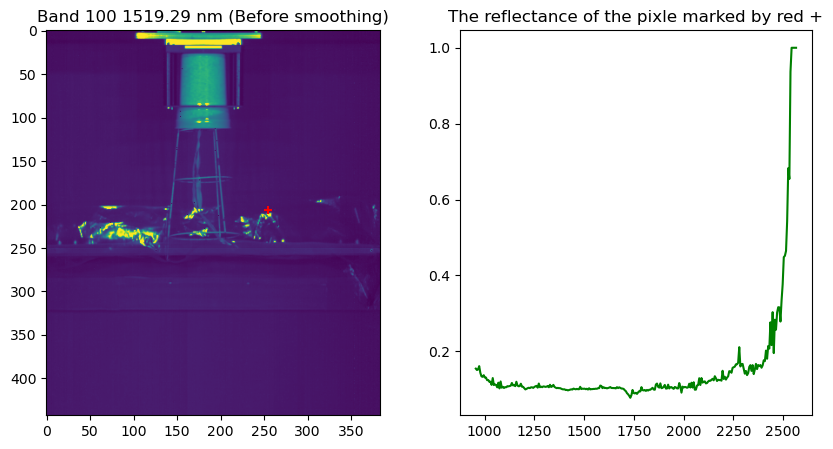

In [8]:
hypcube = envi_funs.calibrate_hyper_data(raw_data['white'], raw_data['dark'], raw_data['plant'],
                                         trim_rate_t_w=0.1, trim_rate_b_w=0.95)


# Check an image
fig1 = plt.figure(figsize=(10, 5))
ax1_f1 = fig1.add_subplot(1,2,1)
ax1_f1.imshow(hypcube[:, :, band_num_check])
ax1_f1.scatter(pix_check[0], pix_check[1], color='red', marker='+')
ax1_f1.set_title('Band ' + str(band_num_check) + ' ' + str(wavelengths[band_num_check]) + ' nm (Before smoothing)')

# Check a ref
a_ref = hypcube[pix_check[0], pix_check[1], :]
ax2_f1 = fig1.add_subplot(1,2,2)
ax2_f1.plot(wavelengths, a_ref, 'g', label='Not smoothed')
ax2_f1.set_title('The reflectance of the pixle marked by red +')
plt.show()                                        


# Smooth the data

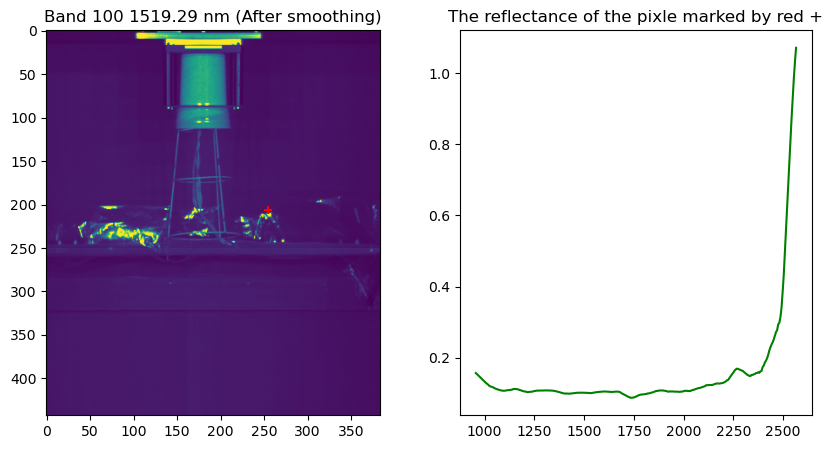

In [9]:
hyp_flat = hypcube.reshape((nrows * ncols, nbands), order='C')
hyp_flat = pp.smooth_savgol_filter(hyp_flat, window_length=wl, polyorder=po)
hypcube = hyp_flat.reshape((nrows, ncols, nbands), order='C')
a_ref = hypcube[pix_check[0], pix_check[1], :]

# Check after smoothing
# Check an image
fig1 = plt.figure(figsize=(10, 5))
ax1_f1 = fig1.add_subplot(1,2,1)
ax1_f1.imshow(hypcube[:, :, band_num_check])
ax1_f1.scatter(pix_check[0], pix_check[1], color='red', marker='+')
ax1_f1.set_title('Band ' + str(band_num_check) + ' ' + str(wavelengths[band_num_check]) + ' nm (After smoothing)')

# Check a ref
a_ref = hypcube[pix_check[0], pix_check[1], :]
ax2_f1 = fig1.add_subplot(1,2,2)
ax2_f1.plot(wavelengths, a_ref, 'g', label='Not smoothed')
ax2_f1.set_title('The reflectance of the pixle marked by red +')
plt.show()     

# Remove the noisy bands

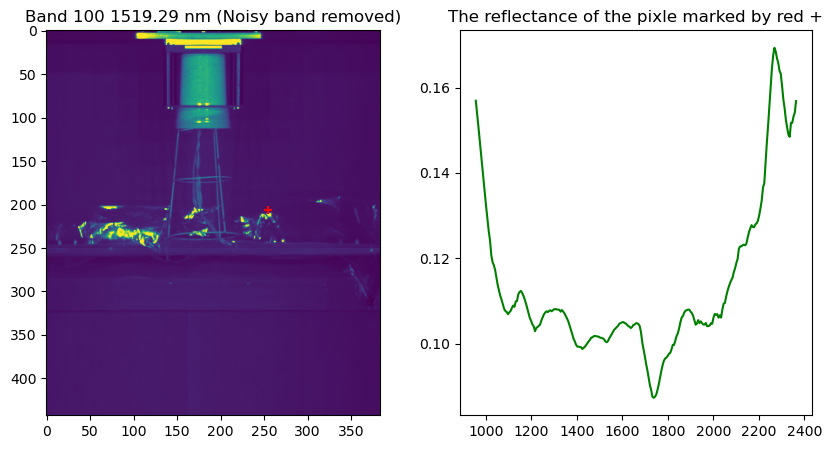

In [10]:
data_type = data_name[0:4]
if data_type== 'vnir':
    good_band_start = 42
    good_band_stop = 440
else:
    good_band_start = 0
    good_band_stop = 251

hypcube = hypcube[:,:,good_band_start:good_band_stop+1]
wavelengths = wavelengths[good_band_start: good_band_stop+1]
a_ref = hypcube[pix_check[0], pix_check[1], :]

# Check an image
fig1 = plt.figure(figsize=(10, 5))
ax1_f1 = fig1.add_subplot(1,2,1)
ax1_f1.imshow(hypcube[:, :, band_num_check])
ax1_f1.scatter(pix_check[0], pix_check[1], color='red', marker='+')
ax1_f1.set_title('Band ' + str(band_num_check) + ' ' + str(wavelengths[band_num_check]) + ' nm (Noisy band removed)')

# Check a ref
a_ref = hypcube[pix_check[0], pix_check[1], :]
ax2_f1 = fig1.add_subplot(1,2,2)
ax2_f1.plot(wavelengths, a_ref, 'g', label='Not smoothed')
ax2_f1.set_title('The reflectance of the pixle marked by red +')
plt.show()     
